# TA047 - Ciencia de Datos (FIUBA)
## Trabajo Práctico 1 - Grupo 03
### EJ3: Competencia de Machine Learning - Predicción de Cancelación de Reservas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import xgboost as xgb

from pathlib import Path

# Buscar datasets/ desde la raíz del proyecto o desde notebooks/.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "datasets").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró datasets/. Abrí el notebook dentro del proyecto "
        "y conservá la carpeta datasets/ junto a notebooks/."
    )
dataset_dir = project_root / "datasets" / "ej3"
print("Datos locales:", dataset_dir)

# 1. Carga de datos
train = pd.read_csv(dataset_dir / 'hotels_train.csv')
test = pd.read_csv(dataset_dir / 'hotels_test.csv')

# 2. Función para Feature Engineering
def crear_features(df):
    df = df.copy()

    df['children'] = df['children'].fillna(0)

    # Flags de presencia
    df['has_agent'] = df['agent'].notna().astype(int)
    df['has_company'] = df['company'].notna().astype(int)

    # Convertir identificadores numéricos a string para tratarlos como categóricos
    df['agent'] = df['agent'].astype(str)
    df['company'] = df['company'].astype(str)

    # Ratios y combinaciones del dominio
    df['room_mismatch'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)
    df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
    df['total_guests'] = df['adults'].fillna(0) + df['children'].fillna(0) + df['babies'].fillna(0)
    df['is_alone'] = (df['total_guests'] == 1).astype(int)

    total_history = df['previous_cancellations'] + df['previous_bookings_not_canceled']
    df['cancellation_rate'] = df['previous_cancellations'] / (total_history + 1)

    return df

train_fe = crear_features(train)
test_fe = crear_features(test)

# --- CORRECCIÓN: Eliminar filas con target nulo para evitar ValueError ---
train_fe = train_fe.dropna(subset=['is_canceled']).reset_index(drop=True)

# 3. Definición de listas de columnas
numericas = [
    'lead_time', 'arrival_date_year', 'arrival_date_week_number',
    'arrival_date_day_of_month', 'stays_in_weekend_nights',
    'stays_in_week_nights', 'adults', 'children', 'babies',
    'is_repeated_guest', 'previous_cancellations',
    'previous_bookings_not_canceled', 'booking_changes',
    'days_in_waiting_list', 'adr',
    'required_car_parking_spaces', 'total_of_special_requests',
    'room_mismatch', 'total_stay', 'total_guests', 'is_alone',
    'has_agent', 'has_company', 'cancellation_rate'
]

categoricas = [
    'hotel', 'arrival_date_month', 'meal', 'country',
    'market_segment', 'distribution_channel',
    'reserved_room_type', 'assigned_room_type',
    'deposit_type', 'customer_type', 'agent', 'company'
]

X = train_fe[numericas + categoricas]
y = train_fe['is_canceled'].astype(int)
X_test = test_fe[numericas + categoricas]

# 4. Construcción de Sub-Pipelines por tipo de variable
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

# 5. Unificación en ColumnTransformer
preprocesador = ColumnTransformer([
    ('num', pipeline_num, numericas),
    ('cat', pipeline_cat, categoricas)
])

Datos locales: /home/thiago/fiuba/cdd/tp1/datasets/ej3


EVALUACIÓN DEL MODELO: ÁRBOLES DE DECISIÓN

--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---
Accuracy:  0.84530
Precision: 0.84746
Recall:    0.84532
F1-Macro:  0.84506

Matriz de Confusión en Validación:
[[24961  6011]
 [ 3567 27374]]

--- MÉTRICAS DE ENTRENAMIENTO (Train) ---
Accuracy:  0.85593
Precision: 0.85744
Recall:    0.85594
F1-Macro:  0.85578

Matriz de Confusión en Entrenamiento:
[[25503  5469]
 [ 3451 27490]]

Archivo Kaggle generado: 'submission_dt.csv'


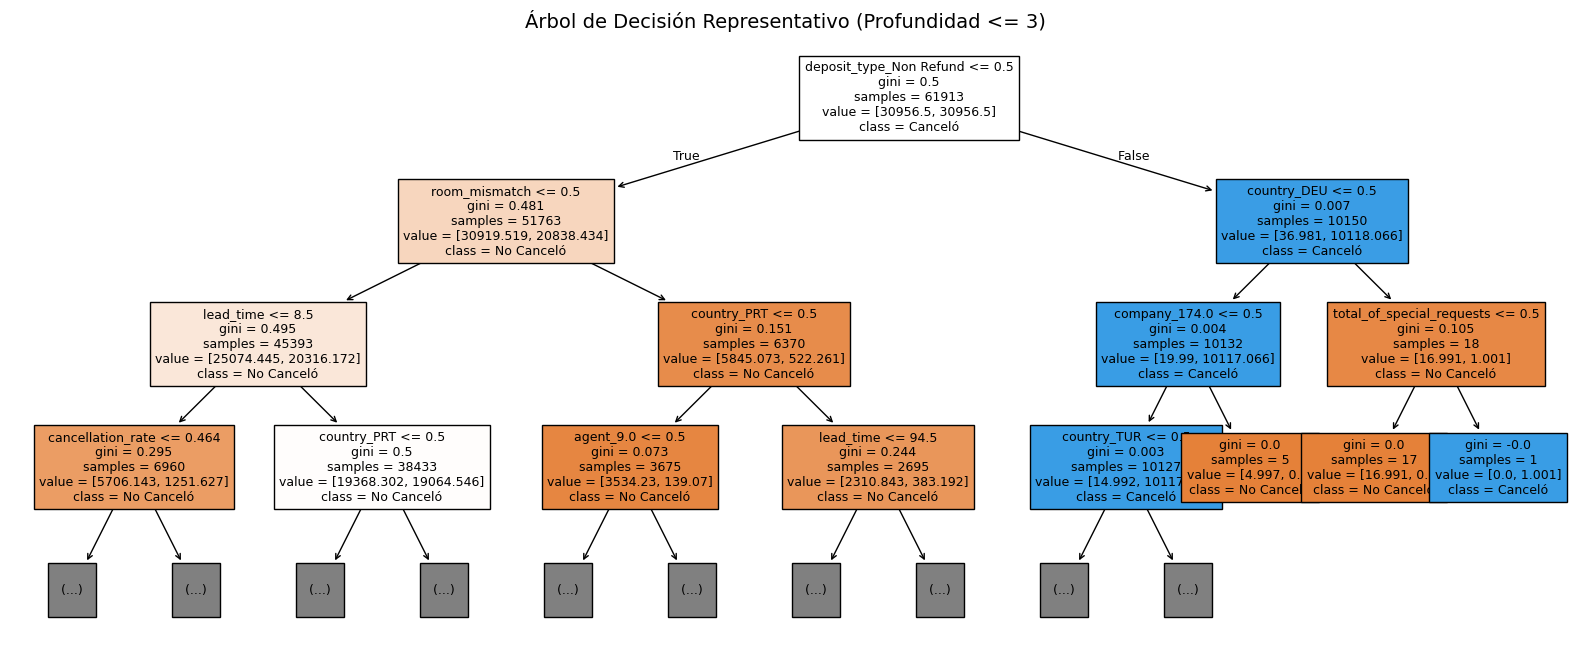

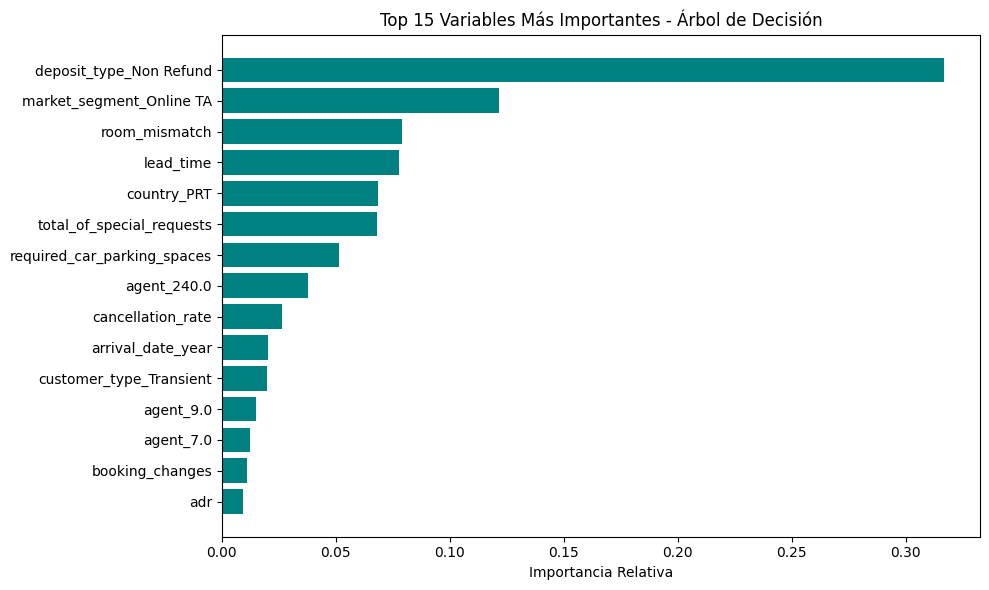

In [2]:
# ============================================================
# MODELO 1: ÁRBOLES DE DECISIÓN
# ============================================================

# Pipeline Árbol de Decisión
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clf', DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        class_weight='balanced',
        random_state=123
    ))
])

# Evaluación en Validación (5-Fold Cross-Validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("EVALUACIÓN DEL MODELO: ÁRBOLES DE DECISIÓN")
print("=" * 60)

y_pred_val = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)

acc_val = accuracy_score(y, y_pred_val)
prec_val = precision_score(y, y_pred_val, average='macro')
rec_val = recall_score(y, y_pred_val, average='macro')
f1_val = f1_score(y, y_pred_val, average='macro')

print("\n--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---")
print(f"Accuracy:  {acc_val:.5f}")
print(f"Precision: {prec_val:.5f}")
print(f"Recall:    {rec_val:.5f}")
print(f"F1-Macro:  {f1_val:.5f}")

print("\nMatriz de Confusión en Validación:")
print(confusion_matrix(y, y_pred_val))

# Evaluación en Entrenamiento (Train)
modelo.fit(X, y)
y_pred_train = modelo.predict(X)

acc_tr = accuracy_score(y, y_pred_train)
prec_tr = precision_score(y, y_pred_train, average='macro')
rec_tr = recall_score(y, y_pred_train, average='macro')
f1_tr = f1_score(y, y_pred_train, average='macro')

print("\n--- MÉTRICAS DE ENTRENAMIENTO (Train) ---")
print(f"Accuracy:  {acc_tr:.5f}")
print(f"Precision: {prec_tr:.5f}")
print(f"Recall:    {rec_tr:.5f}")
print(f"F1-Macro:  {f1_tr:.5f}")

print("\nMatriz de Confusión en Entrenamiento:")
print(confusion_matrix(y, y_pred_train))

# Generación de predicciones para Kaggle
predicciones = modelo.predict(X_test)
submission = pd.DataFrame({'id': test['id'], 'is_canceled': predicciones})
submission.to_csv('submission_dt.csv', index=False)
print("\nArchivo Kaggle generado: 'submission_dt.csv'")

# Visualización del Árbol Representativo (Primeros 3 niveles para legibilidad)
feature_names = modelo.named_steps['preprocesamiento'].get_feature_names_out()
feature_names_clean = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

plt.figure(figsize=(20, 8))
plot_tree(
    modelo.named_steps['clf'],
    max_depth=3,
    feature_names=feature_names_clean,
    class_names=['No Canceló', 'Canceló'],
    filled=True,
    fontsize=9
)
plt.title("Árbol de Decisión Representativo (Profundidad <= 3)", fontsize=14)
plt.show()

# Importancia de Atributos
importancias = modelo.named_steps['clf'].feature_importances_
df_imp = pd.DataFrame({'Feature': feature_names_clean, 'Importancia': importancias}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_imp['Feature'].head(15)[::-1], df_imp['Importancia'].head(15)[::-1], color='teal')
plt.xlabel('Importancia Relativa')
plt.title('Top 15 Variables Más Importantes - Árbol de Decisión')
plt.tight_layout()
plt.show()

EVALUACIÓN DEL MODELO: RANDOM FOREST

--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---
Accuracy:  0.88196
Precision: 0.88217
Recall:    0.88196
F1-Macro:  0.88195

Matriz de Confusión en Validación:
[[27676  3296]
 [ 4012 26929]]

Reporte de Clasificación en Validación:
              precision    recall  f1-score   support

           0       0.87      0.89      0.88     30972
           1       0.89      0.87      0.88     30941

    accuracy                           0.88     61913
   macro avg       0.88      0.88      0.88     61913
weighted avg       0.88      0.88      0.88     61913


--- MÉTRICAS DE ENTRENAMIENTO (Train) ---
Accuracy:  0.98907
Precision: 0.98907
Recall:    0.98906
F1-Macro:  0.98907

Matriz de Confusión en Entrenamiento:
[[30673   299]
 [  378 30563]]

Archivo Kaggle generado: 'submission_rf.csv'


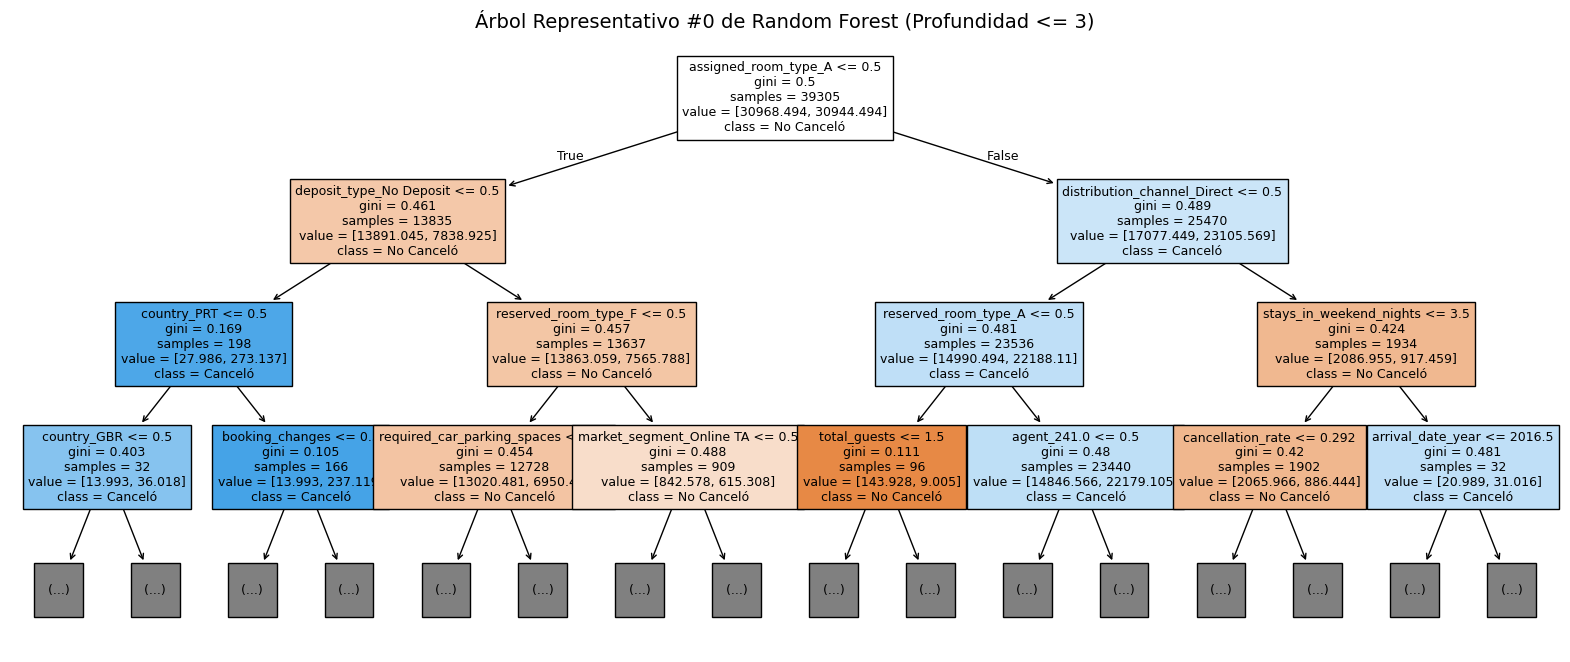

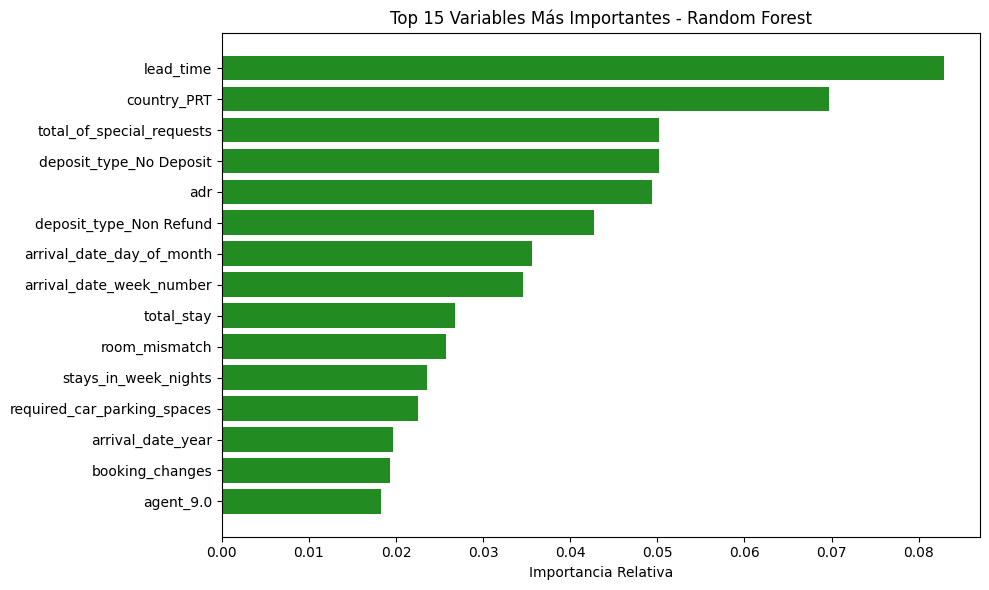

In [3]:
# ============================================================
# MODELO 2: RANDOM FOREST
# ============================================================

# Pipeline Final con Random Forest
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        max_depth=100,
        min_samples_split=4,
        class_weight='balanced',
        random_state=123,
        n_jobs=-1
    ))
])

# Evaluación en Validación (5-Fold Cross-Validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("EVALUACIÓN DEL MODELO: RANDOM FOREST")
print("=" * 60)

y_pred_val = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)

acc_val = accuracy_score(y, y_pred_val)
prec_val = precision_score(y, y_pred_val, average='macro')
rec_val = recall_score(y, y_pred_val, average='macro')
f1_val = f1_score(y, y_pred_val, average='macro')

print("\n--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---")
print(f"Accuracy:  {acc_val:.5f}")
print(f"Precision: {prec_val:.5f}")
print(f"Recall:    {rec_val:.5f}")
print(f"F1-Macro:  {f1_val:.5f}")

print("\nMatriz de Confusión en Validación:")
print(confusion_matrix(y, y_pred_val))

print("\nReporte de Clasificación en Validación:")
print(classification_report(y, y_pred_val))

# Evaluación en Entrenamiento (Train)
modelo.fit(X, y)
y_pred_train = modelo.predict(X)

acc_tr = accuracy_score(y, y_pred_train)
prec_tr = precision_score(y, y_pred_train, average='macro')
rec_tr = recall_score(y, y_pred_train, average='macro')
f1_tr = f1_score(y, y_pred_train, average='macro')

print("\n--- MÉTRICAS DE ENTRENAMIENTO (Train) ---")
print(f"Accuracy:  {acc_tr:.5f}")
print(f"Precision: {prec_tr:.5f}")
print(f"Recall:    {rec_tr:.5f}")
print(f"F1-Macro:  {f1_tr:.5f}")

print("\nMatriz de Confusión en Entrenamiento:")
print(confusion_matrix(y, y_pred_train))

# Generación de predicciones para Kaggle
predicciones = modelo.predict(X_test)
submission = pd.DataFrame({'id': test['id'], 'is_canceled': predicciones})
submission.to_csv('submission_rf.csv', index=False)
print("\nArchivo Kaggle generado: 'submission_rf.csv'")

# Visualización del Árbol Representativo (#0 del Ensamble)
feature_names = modelo.named_steps['preprocesamiento'].get_feature_names_out()
feature_names_clean = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

primer_arbol = modelo.named_steps['clf'].estimators_[0]

plt.figure(figsize=(20, 8))
plot_tree(
    primer_arbol,
    max_depth=3,
    feature_names=feature_names_clean,
    class_names=['No Canceló', 'Canceló'],
    filled=True,
    fontsize=9
)
plt.title("Árbol Representativo #0 de Random Forest (Profundidad <= 3)", fontsize=14)
plt.show()

# Importancia de Atributos (Feature Importance)
importancias = modelo.named_steps['clf'].feature_importances_
df_imp = pd.DataFrame({'Feature': feature_names_clean, 'Importancia': importancias}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_imp['Feature'].head(15)[::-1], df_imp['Importancia'].head(15)[::-1], color='forestgreen')
plt.xlabel('Importancia Relativa')
plt.title('Top 15 Variables Más Importantes - Random Forest')
plt.tight_layout()
plt.show()

EVALUACIÓN DEL MODELO: XGBOOST

--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---
Accuracy:  0.87836
Precision: 0.87843
Recall:    0.87836
F1-Macro:  0.87836

Matriz de Confusión en Validación:
[[27001  3971]
 [ 3560 27381]]

Reporte de Clasificación en Validación:
              precision    recall  f1-score   support

           0       0.88      0.87      0.88     30972
           1       0.87      0.88      0.88     30941

    accuracy                           0.88     61913
   macro avg       0.88      0.88      0.88     61913
weighted avg       0.88      0.88      0.88     61913


--- MÉTRICAS DE ENTRENAMIENTO (Train) ---
Accuracy:  0.90162
Precision: 0.90171
Recall:    0.90162
F1-Macro:  0.90162

Matriz de Confusión en Entrenamiento:
[[27691  3281]
 [ 2810 28131]]

Archivo Kaggle generado: 'submission_xgb.csv'


<Figure size 2200x1000 with 0 Axes>

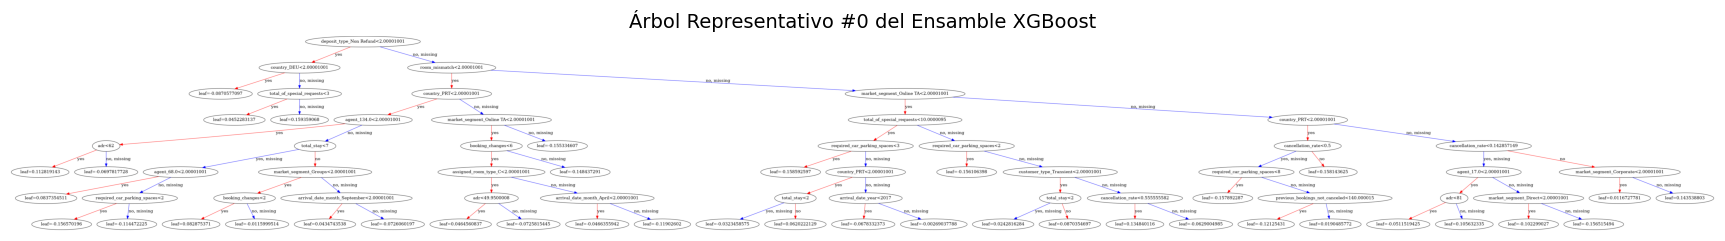

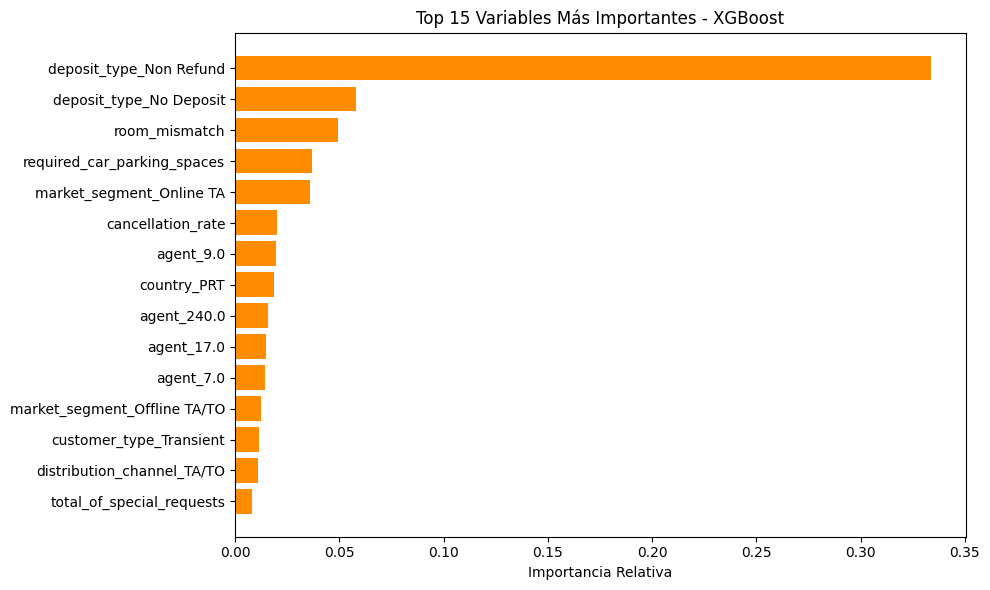

In [4]:
# ============================================================
# MODELO 3: XGBOOST
# ============================================================

# Pipeline Final con XGBoost (incluye poda gamma y regularizaciones L1/L2)
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clf', XGBClassifier(
        n_estimators=350,
        learning_rate=0.08,
        max_depth=7,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1.0,                   # Poda de nodos con poca ganancia
        reg_alpha=0.1,                # Regularización L1 (Lasso)
        reg_lambda=1.5,               # Regularización L2 (Ridge)
        random_state=123,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

# Evaluación en Validación (5-Fold Cross-Validation Out-Of-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("EVALUACIÓN DEL MODELO: XGBOOST")
print("=" * 60)

y_pred_val = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)

acc_val = accuracy_score(y, y_pred_val)
prec_val = precision_score(y, y_pred_val, average='macro')
rec_val = recall_score(y, y_pred_val, average='macro')
f1_val = f1_score(y, y_pred_val, average='macro')

print("\n--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---")
print(f"Accuracy:  {acc_val:.5f}")
print(f"Precision: {prec_val:.5f}")
print(f"Recall:    {rec_val:.5f}")
print(f"F1-Macro:  {f1_val:.5f}")

print("\nMatriz de Confusión en Validación:")
print(confusion_matrix(y, y_pred_val))

print("\nReporte de Clasificación en Validación:")
print(classification_report(y, y_pred_val))

# Evaluación en Entrenamiento (Train)
modelo.fit(X, y)
y_pred_train = modelo.predict(X)

acc_tr = accuracy_score(y, y_pred_train)
prec_tr = precision_score(y, y_pred_train, average='macro')
rec_tr = recall_score(y, y_pred_train, average='macro')
f1_tr = f1_score(y, y_pred_train, average='macro')

print("\n--- MÉTRICAS DE ENTRENAMIENTO (Train) ---")
print(f"Accuracy:  {acc_tr:.5f}")
print(f"Precision: {prec_tr:.5f}")
print(f"Recall:    {rec_tr:.5f}")
print(f"F1-Macro:  {f1_tr:.5f}")

print("\nMatriz de Confusión en Entrenamiento:")
print(confusion_matrix(y, y_pred_train))

# Generación de predicciones para Kaggle
predicciones = modelo.predict(X_test)
submission = pd.DataFrame({'id': test['id'], 'is_canceled': predicciones})
submission.to_csv('submission_xgb.csv', index=False)
print("\nArchivo Kaggle generado: 'submission_xgb.csv'")

# Visualización del Árbol Representativo (#0 del Ensamble XGBoost)
feature_names = modelo.named_steps['preprocesamiento'].get_feature_names_out()
feature_names_clean = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

booster = modelo.named_steps['clf'].get_booster()
booster.feature_names = feature_names_clean

# Graphviz es opcional: si falta dot, continuar con los demás resultados.
from shutil import which

if which("dot") is not None:
    plt.figure(figsize=(22, 10))
    xgb.plot_tree(booster, tree_idx=0, rankdir='TB')
    fig = plt.gcf()
    fig.set_size_inches(22, 10)
    plt.title("Árbol Representativo #0 del Ensamble XGBoost", fontsize=14)
    plt.show()
else:
    print(
        "No se dibuja el árbol de XGBoost porque falta Graphviz (dot). "
        "En Ubuntu: sudo apt install graphviz. "
        "Las métricas, predicciones y demás gráficos se generan igualmente."
    )

# Importancia de Atributos (Feature Importance)
importancias = modelo.named_steps['clf'].feature_importances_
df_imp = pd.DataFrame({'Feature': feature_names_clean, 'Importancia': importancias}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_imp['Feature'].head(15)[::-1], df_imp['Importancia'].head(15)[::-1], color='darkorange')
plt.xlabel('Importancia Relativa')
plt.title('Top 15 Variables Más Importantes - XGBoost')
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# MODELO 4: ENSAMBLE VOTING
# ============================================================

# Modelos Base Fuertes
pipe_rf = Pipeline([
    ('prep', preprocesador),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        max_depth=100,
        min_samples_split=4,
        class_weight='balanced',
        random_state=123,
        n_jobs=-1
    ))
])

pipe_xgb = Pipeline([
    ('prep', preprocesador),
    ('clf', XGBClassifier(
        n_estimators=350,
        learning_rate=0.08,
        max_depth=7,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1.0,
        reg_alpha=0.1,
        reg_lambda=1.5,
        random_state=123,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

# Voting combinando únicamente los clasificadores de alto desempeño
voting_model = VotingClassifier(
    estimators=[('rf', pipe_rf), ('xgb', pipe_xgb)],
    voting='soft',
    weights=[1, 1]
)

# Evaluación en Validación (5-Fold Cross-Validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("EVALUACIÓN DEL MODELO: VOTING (RF + XGBOOST)")
print("=" * 60)

y_pred_val = cross_val_predict(voting_model, X, y, cv=cv, n_jobs=-1)

acc_val = accuracy_score(y, y_pred_val)
prec_val = precision_score(y, y_pred_val, average='macro')
rec_val = recall_score(y, y_pred_val, average='macro')
f1_val = f1_score(y, y_pred_val, average='macro')

print("\n--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---")
print(f"Accuracy:  {acc_val:.5f}")
print(f"Precision: {prec_val:.5f}")
print(f"Recall:    {rec_val:.5f}")
print(f"F1-Macro:  {f1_val:.5f}")

print("\nMatriz de Confusión en Validación:")
print(confusion_matrix(y, y_pred_val))

# Evaluación en Entrenamiento (Train) y Predicción Final
voting_model.fit(X, y)
y_pred_train = voting_model.predict(X)

acc_tr = accuracy_score(y, y_pred_train)
prec_tr = precision_score(y, y_pred_train, average='macro')
rec_tr = recall_score(y, y_pred_train, average='macro')
f1_tr = f1_score(y, y_pred_train, average='macro')

print("\n--- MÉTRICAS DE ENTRENAMIENTO (Train) ---")
print(f"Accuracy:  {acc_tr:.5f}")
print(f"Precision: {prec_tr:.5f}")
print(f"Recall:    {rec_tr:.5f}")
print(f"F1-Macro:  {f1_tr:.5f}")

# Generación del CSV para Kaggle
predicciones = voting_model.predict(X_test)
submission = pd.DataFrame({'id': test['id'], 'is_canceled': predicciones})
submission.to_csv('submission_voting_rf_xgb.csv', index=False)

print("\nArchivo Kaggle generado: 'submission_voting_rf_xgb.csv'")

EVALUACIÓN DEL MODELO: VOTING (RF + XGBOOST)

--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---
Accuracy:  0.88503
Precision: 0.88503
Recall:    0.88503
F1-Macro:  0.88503

Matriz de Confusión en Validación:
[[27443  3529]
 [ 3589 27352]]

--- MÉTRICAS DE ENTRENAMIENTO (Train) ---
Accuracy:  0.95069
Precision: 0.95070
Recall:    0.95069
F1-Macro:  0.95069

Archivo Kaggle generado: 'submission_voting_rf_xgb.csv'


In [6]:
# ============================================================
# MODELO 5: ENSAMBLE STACKING
# ============================================================

# Modelos Base Fuertes (RF + XGBoost)
pipe_rf = Pipeline([
    ('prep', preprocesador),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        max_depth=100,
        min_samples_split=4,
        class_weight='balanced',
        random_state=123,
        n_jobs=-1
    ))
])

pipe_xgb = Pipeline([
    ('prep', preprocesador),
    ('clf', XGBClassifier(
        n_estimators=350,
        learning_rate=0.08,
        max_depth=7,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1.0,
        reg_alpha=0.1,
        reg_lambda=1.5,
        random_state=123,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

# Stacking con Regresión Logística balanceada como Meta-Modelo
stacking_model = StackingClassifier(
    estimators=[('rf', pipe_rf), ('xgb', pipe_xgb)],
    final_estimator=LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=123),
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1
)

# Evaluación en Validación (5-Fold Cross-Validation Out-Of-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("EVALUACIÓN DEL MODELO: STACKING (RF + XGBOOST)")
print("=" * 60)

y_pred_val = cross_val_predict(stacking_model, X, y, cv=cv, n_jobs=-1)

acc_val = accuracy_score(y, y_pred_val)
prec_val = precision_score(y, y_pred_val, average='macro')
rec_val = recall_score(y, y_pred_val, average='macro')
f1_val = f1_score(y, y_pred_val, average='macro')

print("\n--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---")
print(f"Accuracy:  {acc_val:.5f}")
print(f"Precision: {prec_val:.5f}")
print(f"Recall:    {rec_val:.5f}")
print(f"F1-Macro:  {f1_val:.5f}")

print("\nMatriz de Confusión en Validación:")
print(confusion_matrix(y, y_pred_val))

print("\nReporte de Clasificación en Validación:")
print(classification_report(y, y_pred_val))

# Evaluación en Entrenamiento (Train)
stacking_model.fit(X, y)
y_pred_train = stacking_model.predict(X)

acc_tr = accuracy_score(y, y_pred_train)
prec_tr = precision_score(y, y_pred_train, average='macro')
rec_tr = recall_score(y, y_pred_train, average='macro')
f1_tr = f1_score(y, y_pred_train, average='macro')

print("\n--- MÉTRICAS DE ENTRENAMIENTO (Train) ---")
print(f"Accuracy:  {acc_tr:.5f}")
print(f"Precision: {prec_tr:.5f}")
print(f"Recall:    {rec_tr:.5f}")
print(f"F1-Macro:  {f1_tr:.5f}")

print("\nMatriz de Confusión en Entrenamiento:")
print(confusion_matrix(y, y_pred_train))

# Generación de predicciones para Kaggle
predicciones = stacking_model.predict(X_test)
submission = pd.DataFrame({'id': test['id'], 'is_canceled': predicciones})
submission.to_csv('submission_stacking.csv', index=False)

print("\nArchivo Kaggle generado: 'submission_stacking.csv'")

EVALUACIÓN DEL MODELO: STACKING (RF + XGBOOST)

--- MÉTRICAS DE VALIDACIÓN (5-Fold OOF) ---
Accuracy:  0.88561
Precision: 0.88561
Recall:    0.88561
F1-Macro:  0.88561

Matriz de Confusión en Validación:
[[27437  3535]
 [ 3547 27394]]

Reporte de Clasificación en Validación:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89     30972
           1       0.89      0.89      0.89     30941

    accuracy                           0.89     61913
   macro avg       0.89      0.89      0.89     61913
weighted avg       0.89      0.89      0.89     61913


--- MÉTRICAS DE ENTRENAMIENTO (Train) ---
Accuracy:  0.96569
Precision: 0.96570
Recall:    0.96570
F1-Macro:  0.96569

Matriz de Confusión en Entrenamiento:
[[29833  1139]
 [  985 29956]]

Archivo Kaggle generado: 'submission_stacking.csv'
